In [3]:
import cv2, glob, os
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

CARTELLA = '/content/drive/MyDrive/MozartAI/Foto Prova'
FOTO = sorted(f for ext in ('jpg', 'jpeg', 'png') for f in glob.glob(f'{CARTELLA}/*.{ext}'))
for f in FOTO:
    print(os.path.basename(f))
print(len(FOTO), "foto trovate")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
IMG_3276.jpeg
IMG_3277.jpeg
IMG_3278.jpeg
IMG_3279.jpeg
IMG_3280.jpeg
5 foto trovate


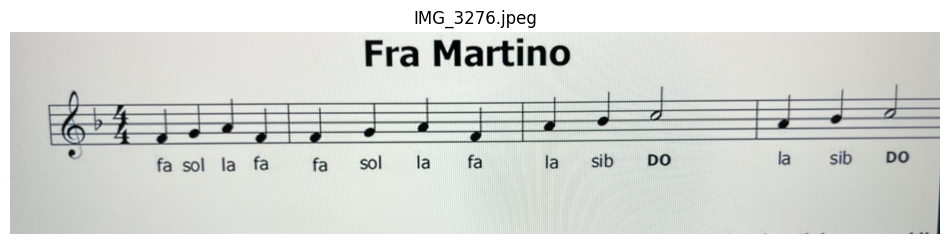

In [4]:
def mostra(img, titolo='', grande=True):
    plt.figure(figsize=(12, 8) if grande else (6, 4))
    if img.ndim == 2:
        plt.imshow(img, cmap='gray')
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))   # OpenCV usa BGR, matplotlib RGB
    plt.title(titolo); plt.axis('off'); plt.show()

img = cv2.imread(FOTO[0])
mostra(img, os.path.basename(FOTO[0]))

In [5]:
for f in FOTO:
    img = cv2.imread(f)
    assert img is not None, f"Non riesco a leggere {f}"
    h, w, canali = img.shape
    print(f"{os.path.basename(f):32s} altezza={h:4d} larghezza={w:4d} canali={canali} "
          f"tipo={img.dtype} min={img.min()} max={img.max()} megapixel={h * w / 1e6:.1f}")

IMG_3276.jpeg                    altezza= 856 larghezza=3942 canali=3 tipo=uint8 min=0 max=255 megapixel=3.4
IMG_3277.jpeg                    altezza=1106 larghezza=4032 canali=3 tipo=uint8 min=0 max=255 megapixel=4.5
IMG_3278.jpeg                    altezza=1215 larghezza=3803 canali=3 tipo=uint8 min=0 max=255 megapixel=4.6
IMG_3279.jpeg                    altezza=1288 larghezza=3785 canali=3 tipo=uint8 min=0 max=255 megapixel=4.9
IMG_3280.jpeg                    altezza=2288 larghezza=3024 canali=3 tipo=uint8 min=0 max=255 megapixel=6.9


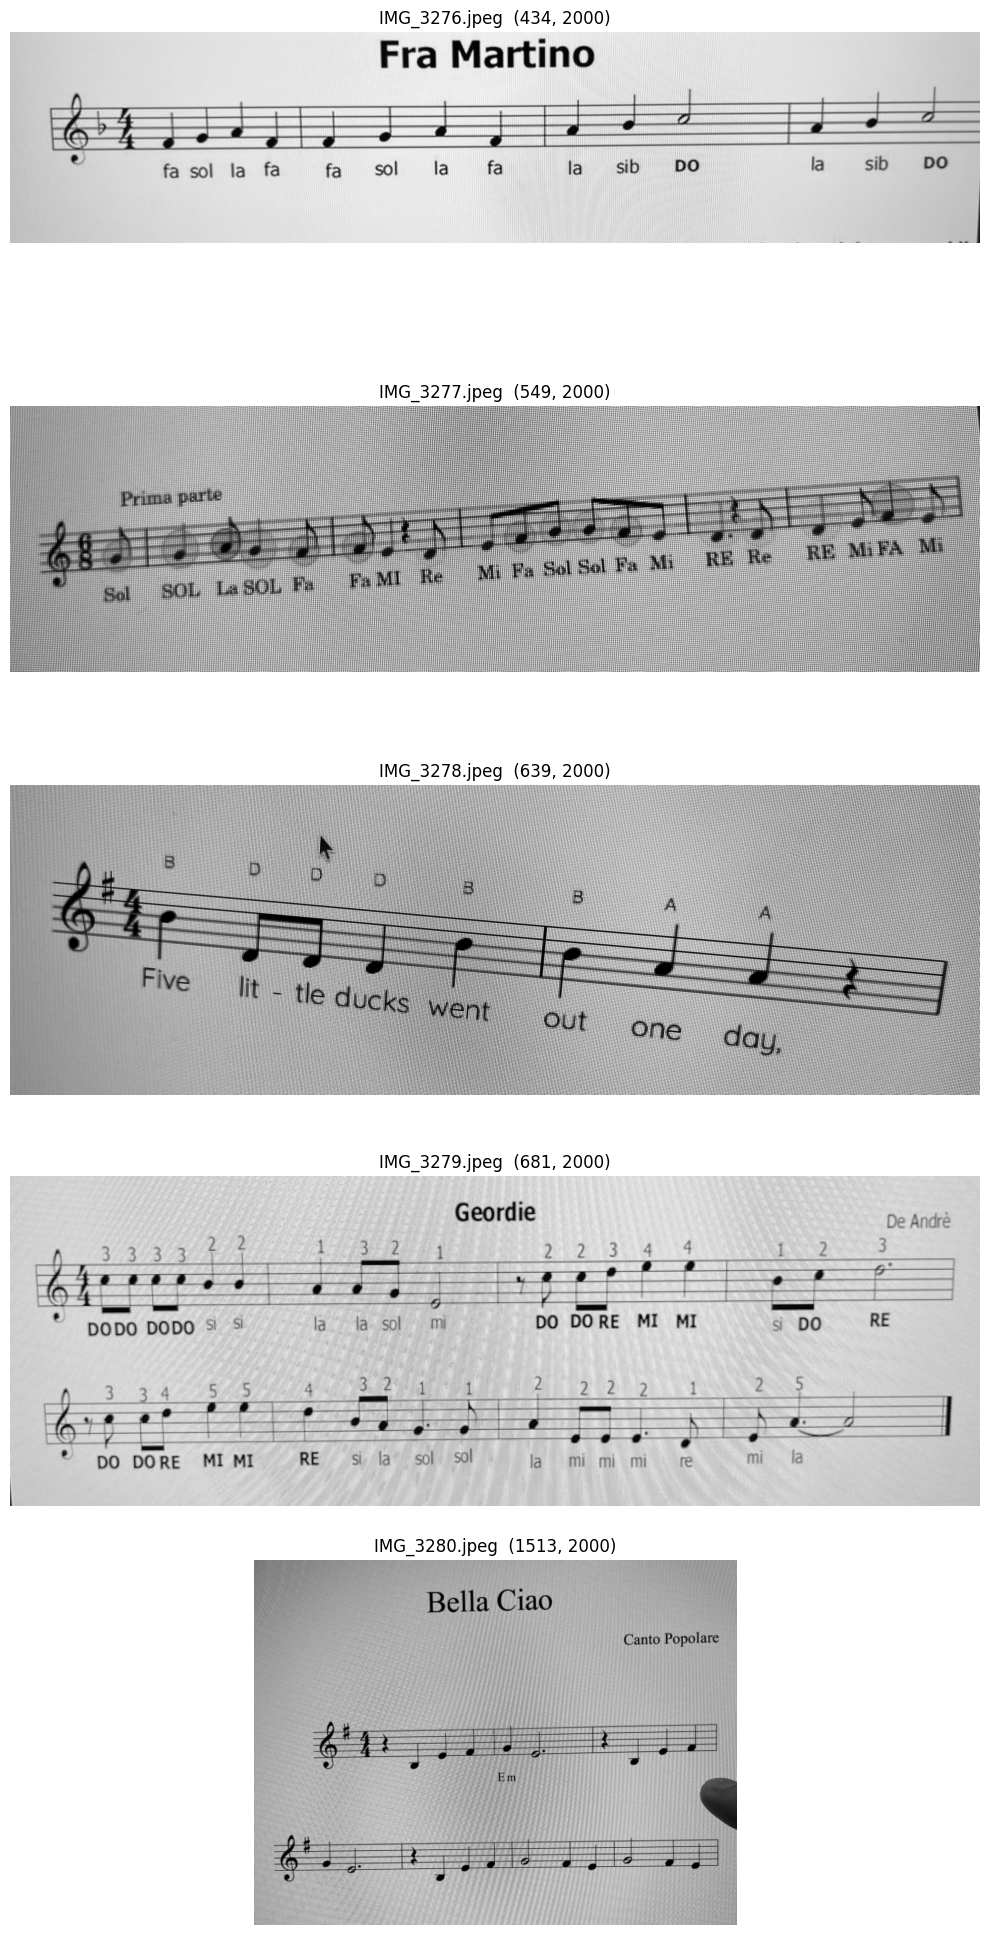

In [6]:
LARGHEZZA = 2000   # larghezza di lavoro: tutte le foto verranno portate a questa

def carica(percorso, larghezza=LARGHEZZA):
    """Legge una foto, la porta alla larghezza di lavoro e restituisce (colore, grigio)."""
    img = cv2.imread(percorso)
    assert img is not None, f"Non riesco a leggere {percorso}"
    h, w = img.shape[:2]
    if w != larghezza:
        nuova_h = round(h * larghezza / w)                       # mantengo le proporzioni
        interp = cv2.INTER_AREA if w > larghezza else cv2.INTER_CUBIC
        img = cv2.resize(img, (larghezza, nuova_h), interpolation=interp)
    grigio = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img, grigio

# Controllo: le 5 foto in grigi, una sotto l'altra
fig, assi = plt.subplots(len(FOTO), 1, figsize=(10, 4 * len(FOTO)))
for ax, f in zip(assi, FOTO):
    colore, grigio = carica(f)
    ax.imshow(grigio, cmap='gray')
    ax.set_title(f"{os.path.basename(f)}  {grigio.shape}")
    ax.axis('off')
plt.tight_layout()
plt.show()

IMG_3276.jpeg                    nero globale: 7.3%   nero adattiva: 9.8%
IMG_3277.jpeg                    nero globale: 49.2%   nero adattiva: 40.6%
IMG_3278.jpeg                    nero globale: 46.6%   nero adattiva: 37.4%
IMG_3279.jpeg                    nero globale: 13.7%   nero adattiva: 25.7%
IMG_3280.jpeg                    nero globale: 44.4%   nero adattiva: 38.1%


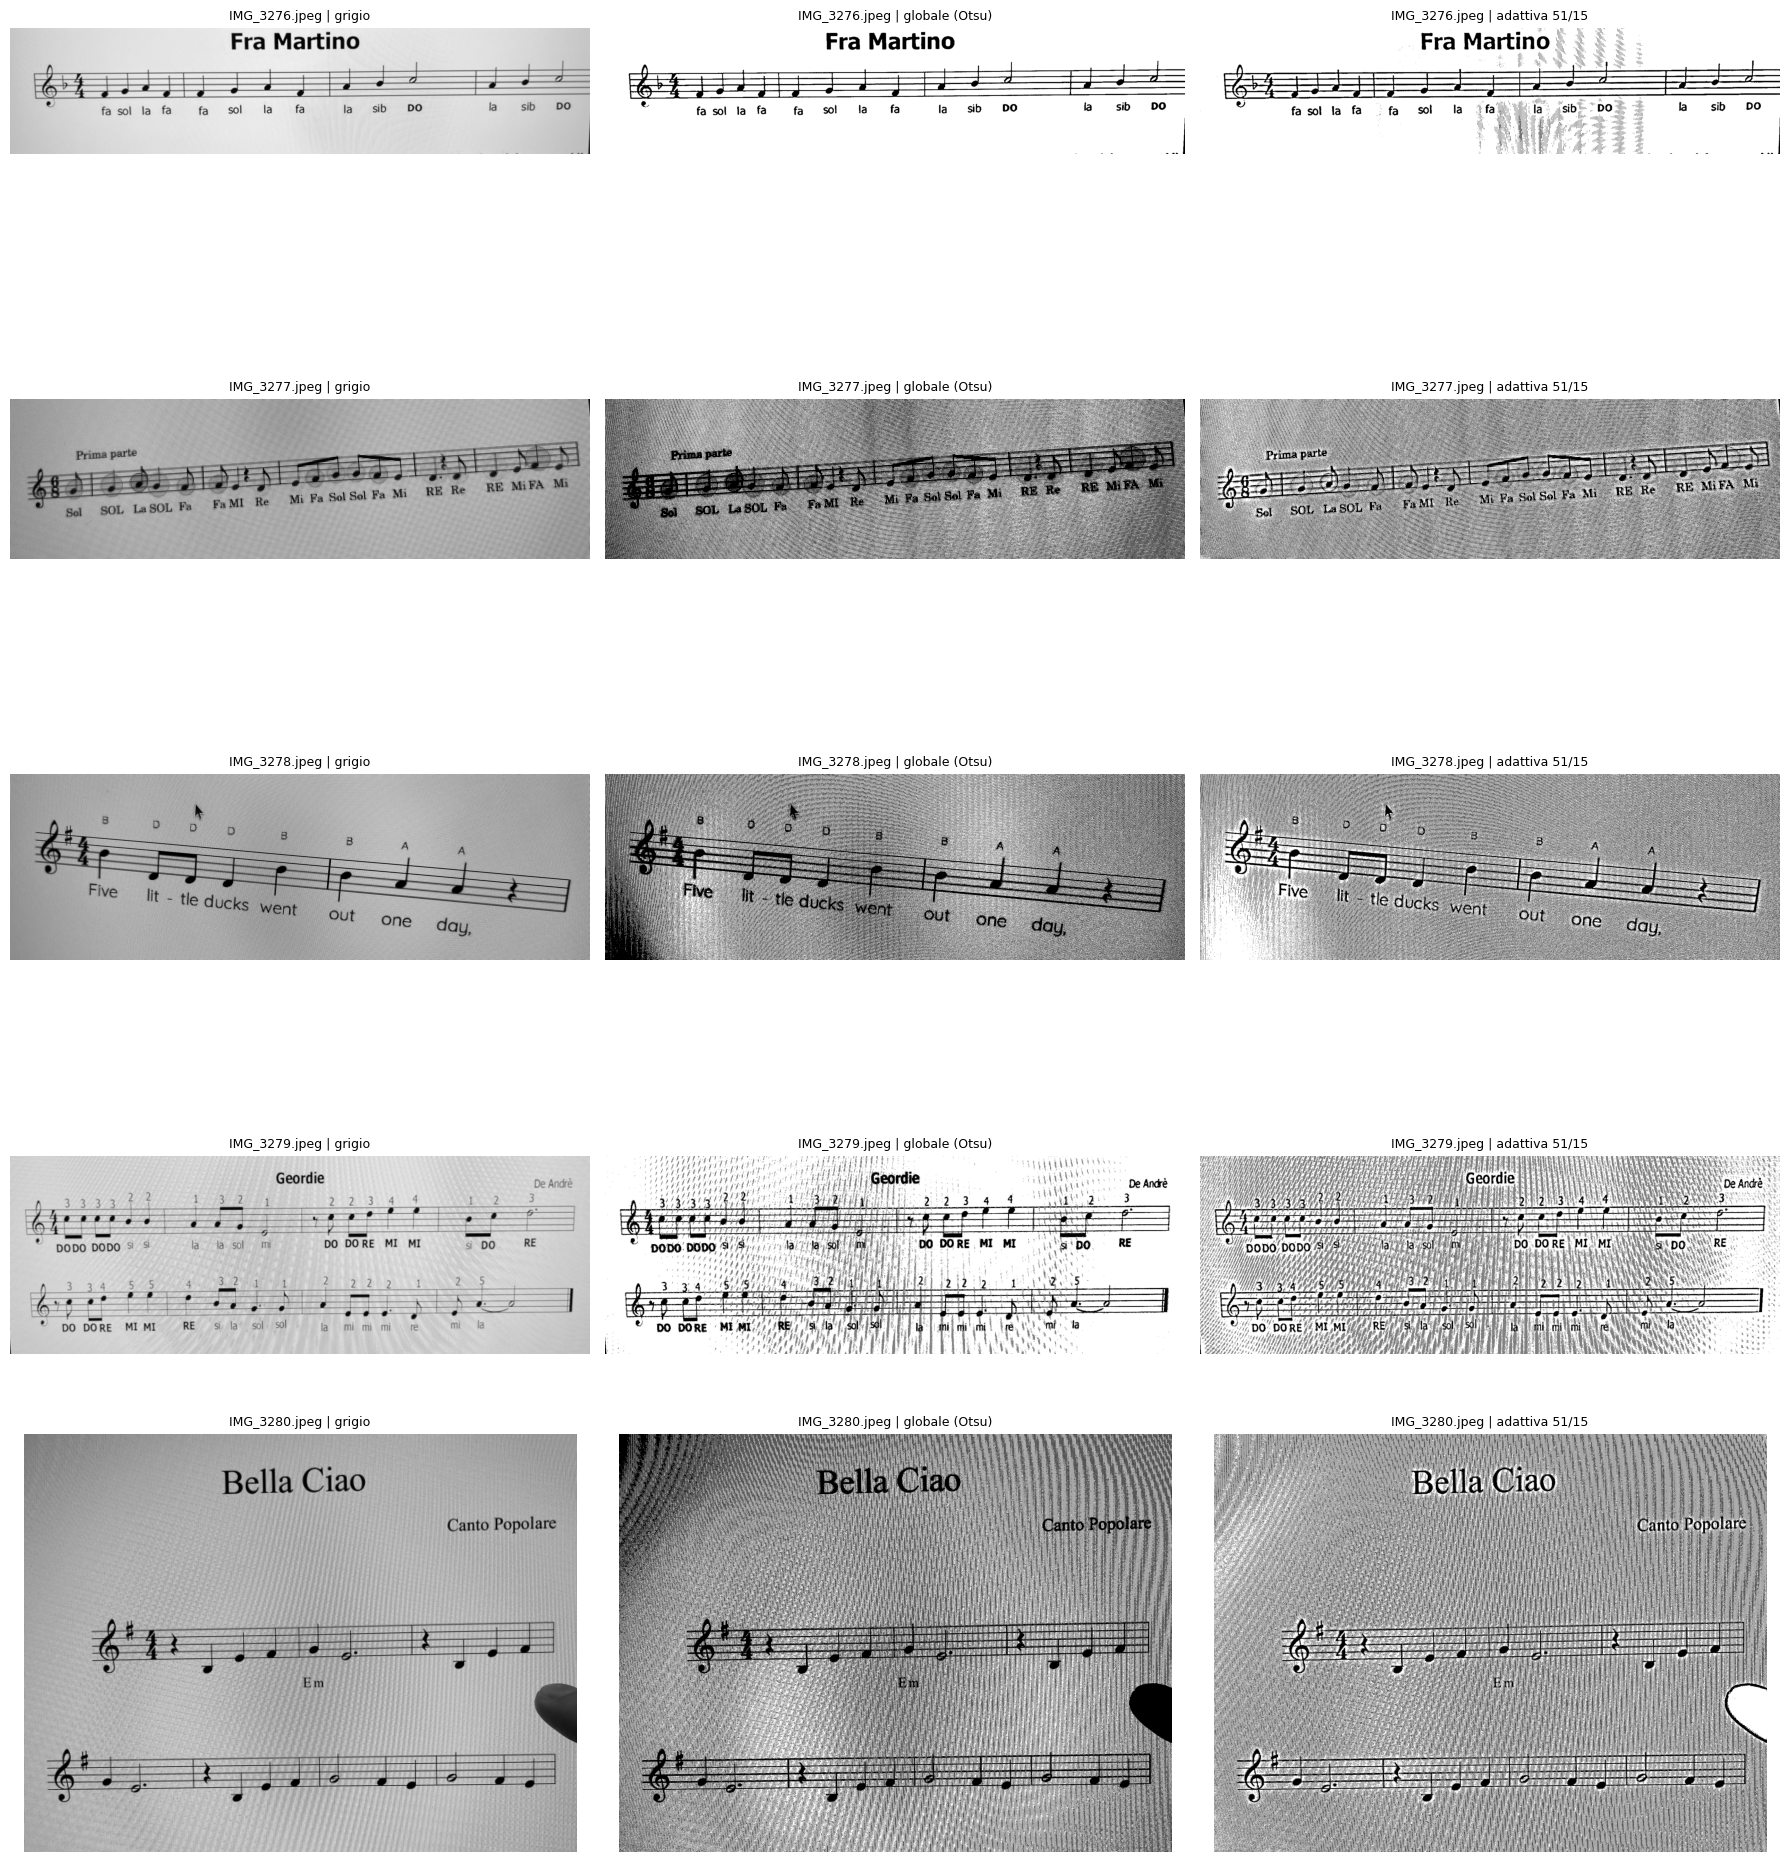

In [7]:
def binarizza_globale(grigio):
    _, b = cv2.threshold(grigio, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return b

def binarizza_adattiva(grigio, block=51, C=15):
    return cv2.adaptiveThreshold(grigio, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, block, C)

fig, assi = plt.subplots(len(FOTO), 3, figsize=(18, 4 * len(FOTO)))
for riga, f in zip(assi, FOTO):
    _, grigio = carica(f)
    g, a = binarizza_globale(grigio), binarizza_adattiva(grigio)
    for ax, im, nome in zip(riga, (grigio, g, a), ('grigio', 'globale (Otsu)', 'adattiva 51/15')):
        ax.imshow(im, cmap='gray'); ax.axis('off')
        ax.set_title(f"{os.path.basename(f)} | {nome}", fontsize=9)
    print(f"{os.path.basename(f):32s} nero globale: {(g == 0).mean():.1%}   nero adattiva: {(a == 0).mean():.1%}")
plt.tight_layout(); plt.show()

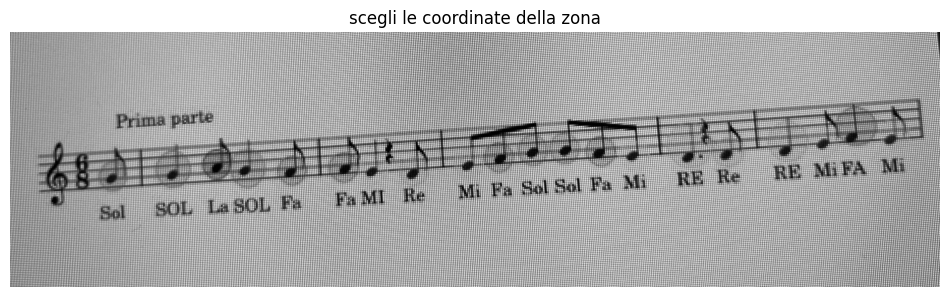

In [8]:
def zoom(img, y0, y1, x0, x1):
    return img[y0:y1, x0:x1]

# Scegli una foto difficile (qui la sfocata: cambia l'indice) e una zona con il pentagramma
colore, grigio = carica(FOTO[1])
mostra(grigio, 'scegli le coordinate della zona')     # guarda gli assi per decidere y0, y1, x0, x1

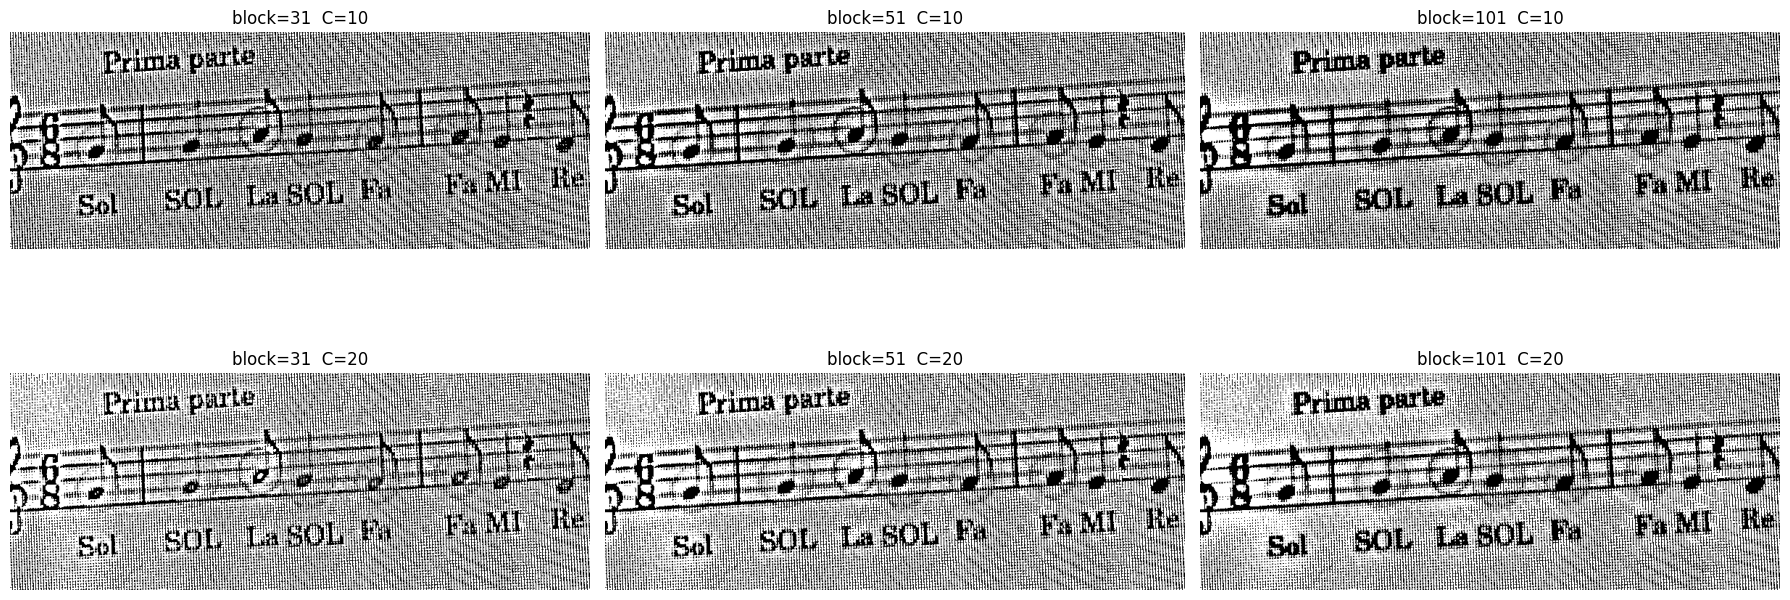

In [9]:
Y0, Y1, X0, X1 = 150, 450, 100, 900     # CAMBIALE con quelle del tuo pentagramma

combinazioni = [(31, 10), (51, 10), (101, 10), (31, 20), (51, 20), (101, 20)]
fig, assi = plt.subplots(2, 3, figsize=(18, 8))
for ax, (block, C) in zip(assi.ravel(), combinazioni):
    b = binarizza_adattiva(grigio, block, C)
    ax.imshow(zoom(b, Y0, Y1, X0, X1), cmap='gray'); ax.axis('off')
    ax.set_title(f"block={block}  C={C}")
plt.tight_layout(); plt.show()

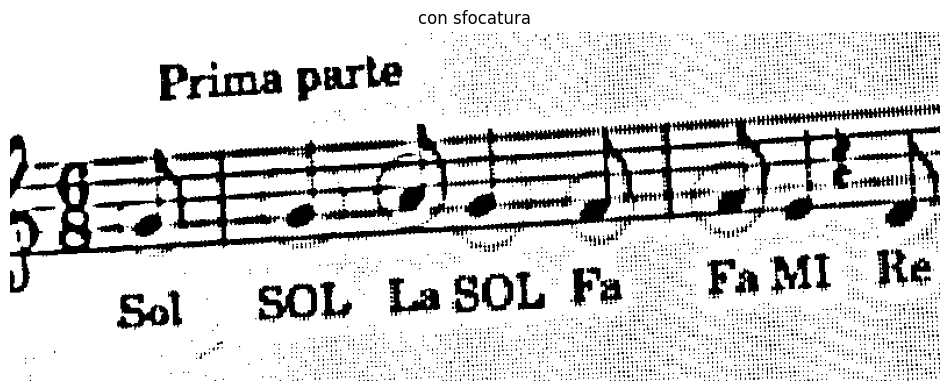

In [10]:
sfocato = cv2.GaussianBlur(grigio, (5, 5), 0)      # prova anche (3, 3) e (7, 7)
b = binarizza_adattiva(sfocato, 51, 15)
mostra(zoom(b, Y0, Y1, X0, X1), 'con sfocatura')

IMG_3276.jpeg                    pixel neri: 8.2%
IMG_3277.jpeg                    pixel neri: 6.1%
IMG_3278.jpeg                    pixel neri: 5.8%
IMG_3279.jpeg                    pixel neri: 8.0%
IMG_3280.jpeg                    pixel neri: 4.4%


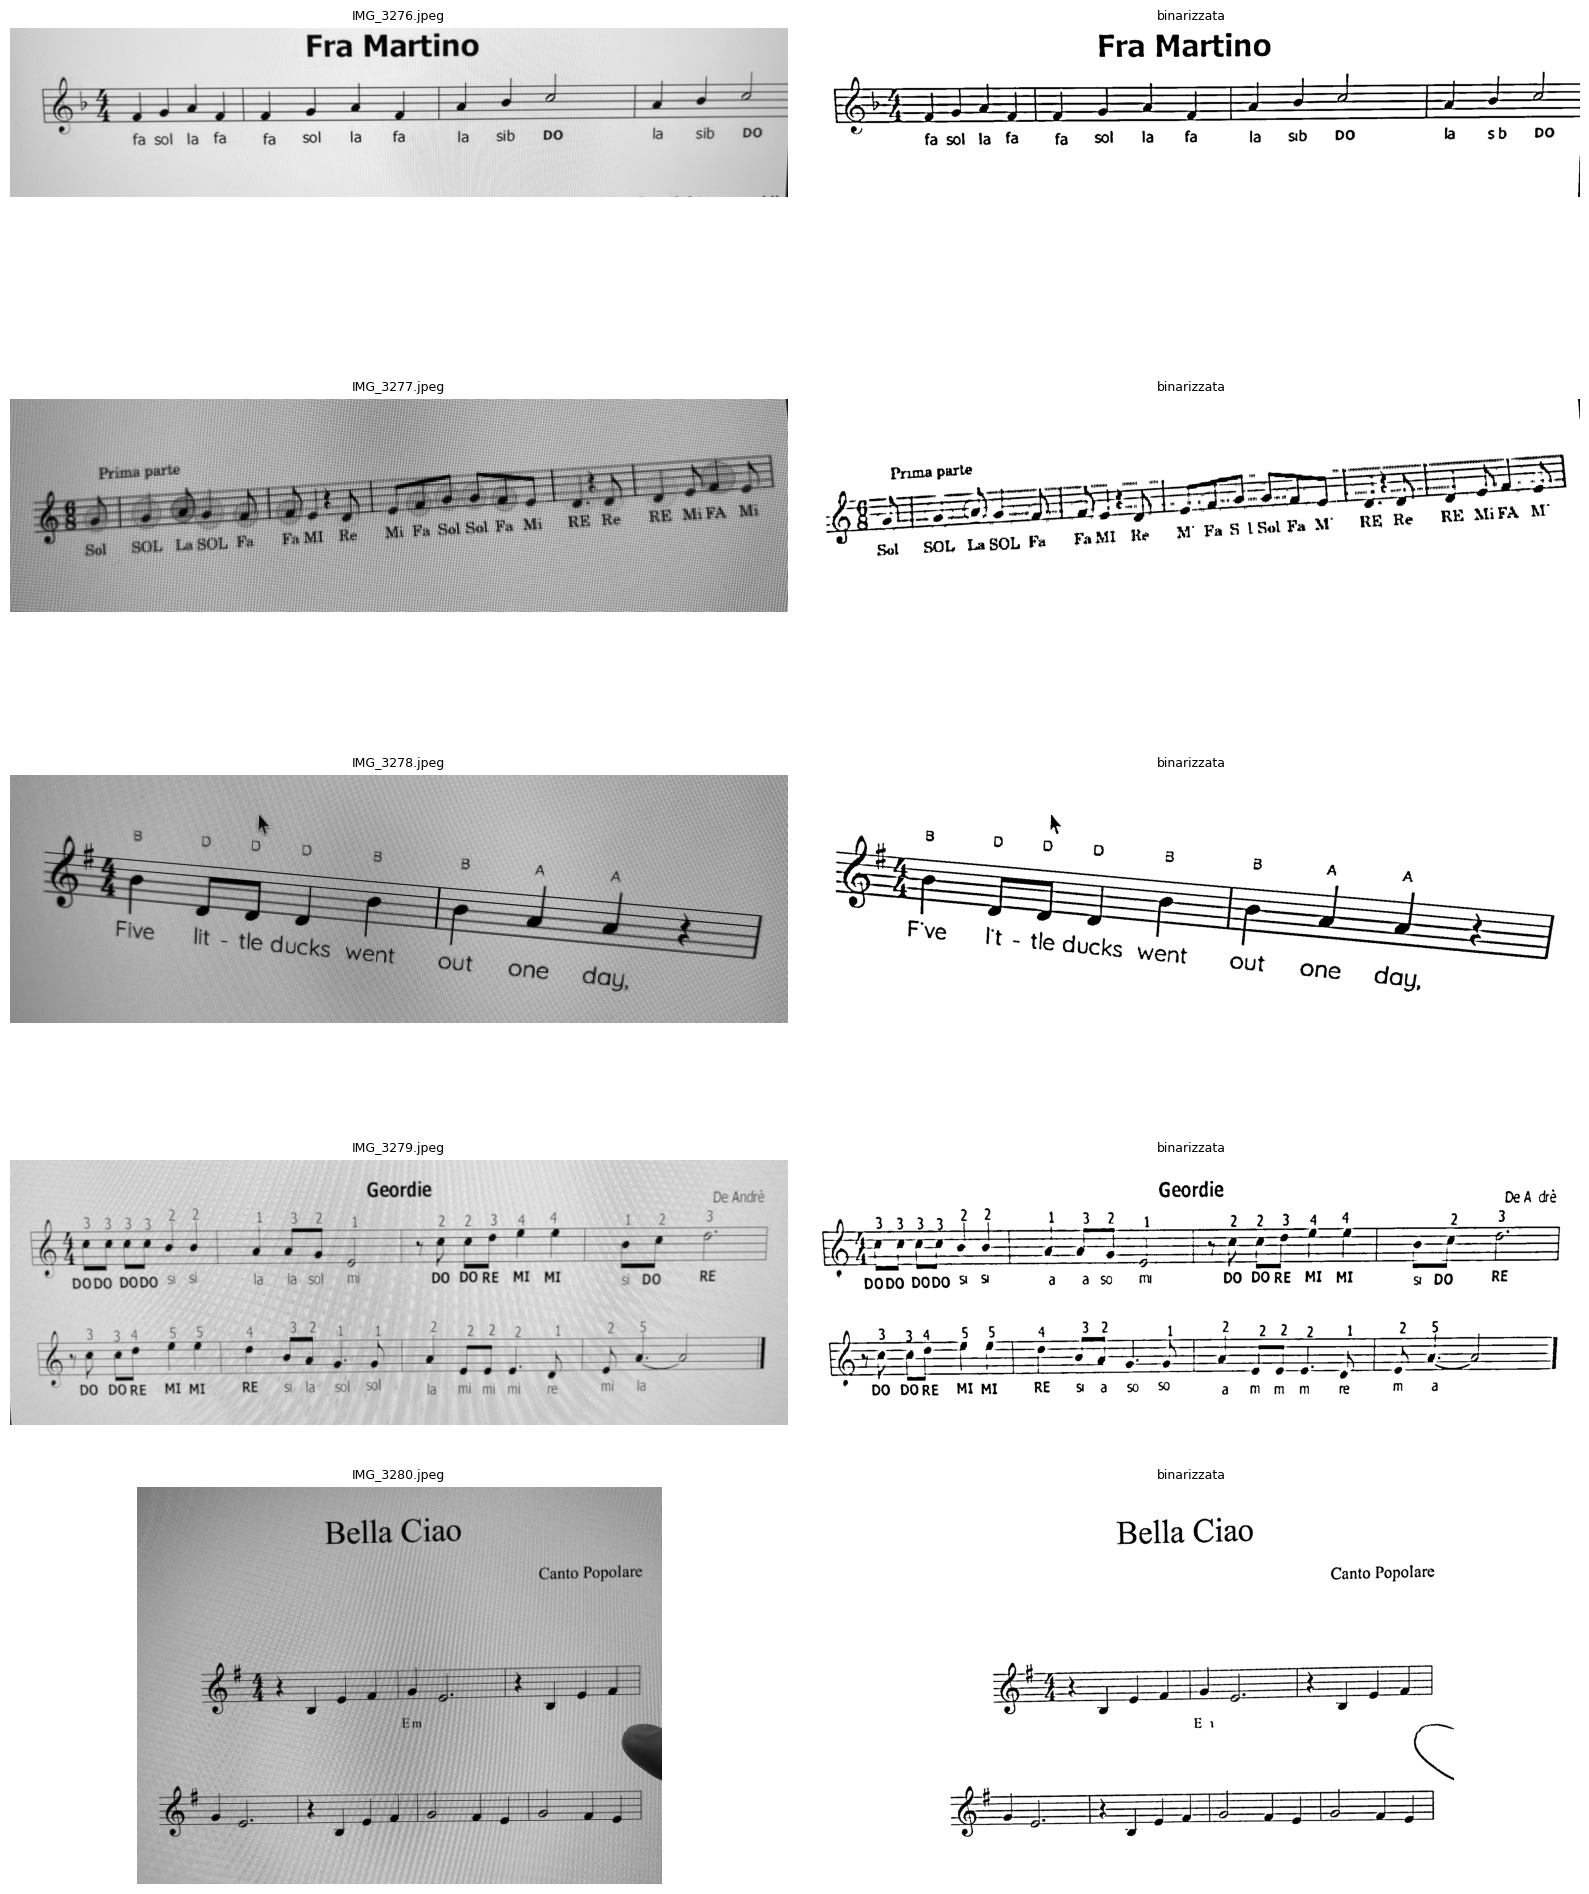

In [11]:
def binarizza(grigio, blur=5, block=51, C=20, min_area=20, max_sottile=150):
    """grigio -> immagine binaria: inchiostro nero (0) su sfondo bianco (255)."""
    # 1) sfocatura leggera: cancella il moiré dello schermo
    g = cv2.GaussianBlur(grigio, (blur, blur), 0)
    # 2) soglia adattiva: ogni pixel confrontato con i vicini
    b = cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                              cv2.THRESH_BINARY, block, C)
    # 3) tolgo i frammenti sottili che restano (trattini del moiré), tenendo i "punti" tondi
    inchiostro = (b == 0).astype(np.uint8)
    n, etichette, st, _ = cv2.connectedComponentsWithStats(inchiostro, connectivity=8)
    area = st[:, cv2.CC_STAT_AREA]
    larg = st[:, cv2.CC_STAT_WIDTH]
    alt = st[:, cv2.CC_STAT_HEIGHT]
    quasi_quadrato = (larg >= 5) & (larg <= 18) & (alt >= 5) & (alt <= 18)   # tipo punto di valore
    tieni = (area >= max_sottile) | ((area >= min_area) & quasi_quadrato)
    tieni[0] = False                                                          # 0 = lo sfondo
    return np.where(tieni[etichette], 0, 255).astype(np.uint8)

# Prova su tutte le foto
fig, assi = plt.subplots(len(FOTO), 2, figsize=(16, 4 * len(FOTO)))
for riga, f in zip(assi, FOTO):
    _, grigio = carica(f)
    b = binarizza(grigio)
    riga[0].imshow(grigio, cmap='gray'); riga[0].set_title(os.path.basename(f), fontsize=9)
    riga[1].imshow(b, cmap='gray');      riga[1].set_title('binarizzata', fontsize=9)
    for ax in riga: ax.axis('off')
    print(f"{os.path.basename(f):32s} pixel neri: {(b == 0).mean():.1%}")
plt.tight_layout(); plt.show()

In [12]:
def ruota(img, angolo, bordo=255, interp=cv2.INTER_LINEAR):
    """Ruota l'immagine di 'angolo' gradi (positivo = antiorario) senza tagliare gli angoli."""
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angolo, 1.0)
    c, s = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * s + w * c), int(h * c + w * s)     # nuove dimensioni: la foto ruotata deve starci tutta
    M[0, 2] += nw / 2 - w / 2
    M[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(img, M, (nw, nh), flags=interp,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=bordo)

def punteggio(ink, angolo):
    """Quanto sono 'nette' le righe se ruoto di questo angolo? Alto = righe ben allineate."""
    r = ruota(ink, angolo, bordo=0)
    return np.var(r.sum(axis=1).astype(np.float64))     # varianza delle somme per riga

def stima_angolo(binaria, max_angolo=10, scala=0.25):
    ink = (binaria == 0).astype(np.float32)             # inchiostro = 1
    h, w = ink.shape
    ink = ink[:, int(w * 0.08):int(w * 0.92)]           # tolgo i bordi laterali (disturbano)
    piccola = cv2.resize(ink, None, fx=scala, fy=scala, interpolation=cv2.INTER_AREA)   # più veloce
    grossi = np.arange(-max_angolo, max_angolo + 0.01, 1.0)           # prima passi di 1 grado
    a0 = grossi[np.argmax([punteggio(piccola, a) for a in grossi])]
    fini = np.arange(a0 - 1, a0 + 1.01, 0.1)                          # poi passi di 0,1 grado intorno al migliore
    return float(fini[np.argmax([punteggio(piccola, a) for a in fini])])

def raddrizza(binaria):
    """binaria -> (binaria dritta, angolo usato)."""
    angolo = stima_angolo(binaria)
    r = ruota(binaria, angolo, bordo=255)               # bordo bianco
    return np.where(r < 128, 0, 255).astype(np.uint8), angolo    # torno a soli 0 e 255

IMG_3276.jpeg                    stimato=-0.50  Hough prima=-0.49525102160700923  stimato dopo=-0.00  Hough dopo=0.0
IMG_3277.jpeg                    stimato=-3.50  Hough prima=-3.5239494996946705  stimato dopo=-0.00  Hough dopo=0.0
IMG_3278.jpeg                    stimato=+5.20  Hough prima=5.247619351326639  stimato dopo=-0.00  Hough dopo=0.0
IMG_3279.jpeg                    stimato=-0.50  Hough prima=-0.47155955407616096  stimato dopo=-0.00  Hough dopo=0.0
IMG_3280.jpeg                    stimato=-0.80  Hough prima=-0.975339811202278  stimato dopo=-0.00  Hough dopo=0.0


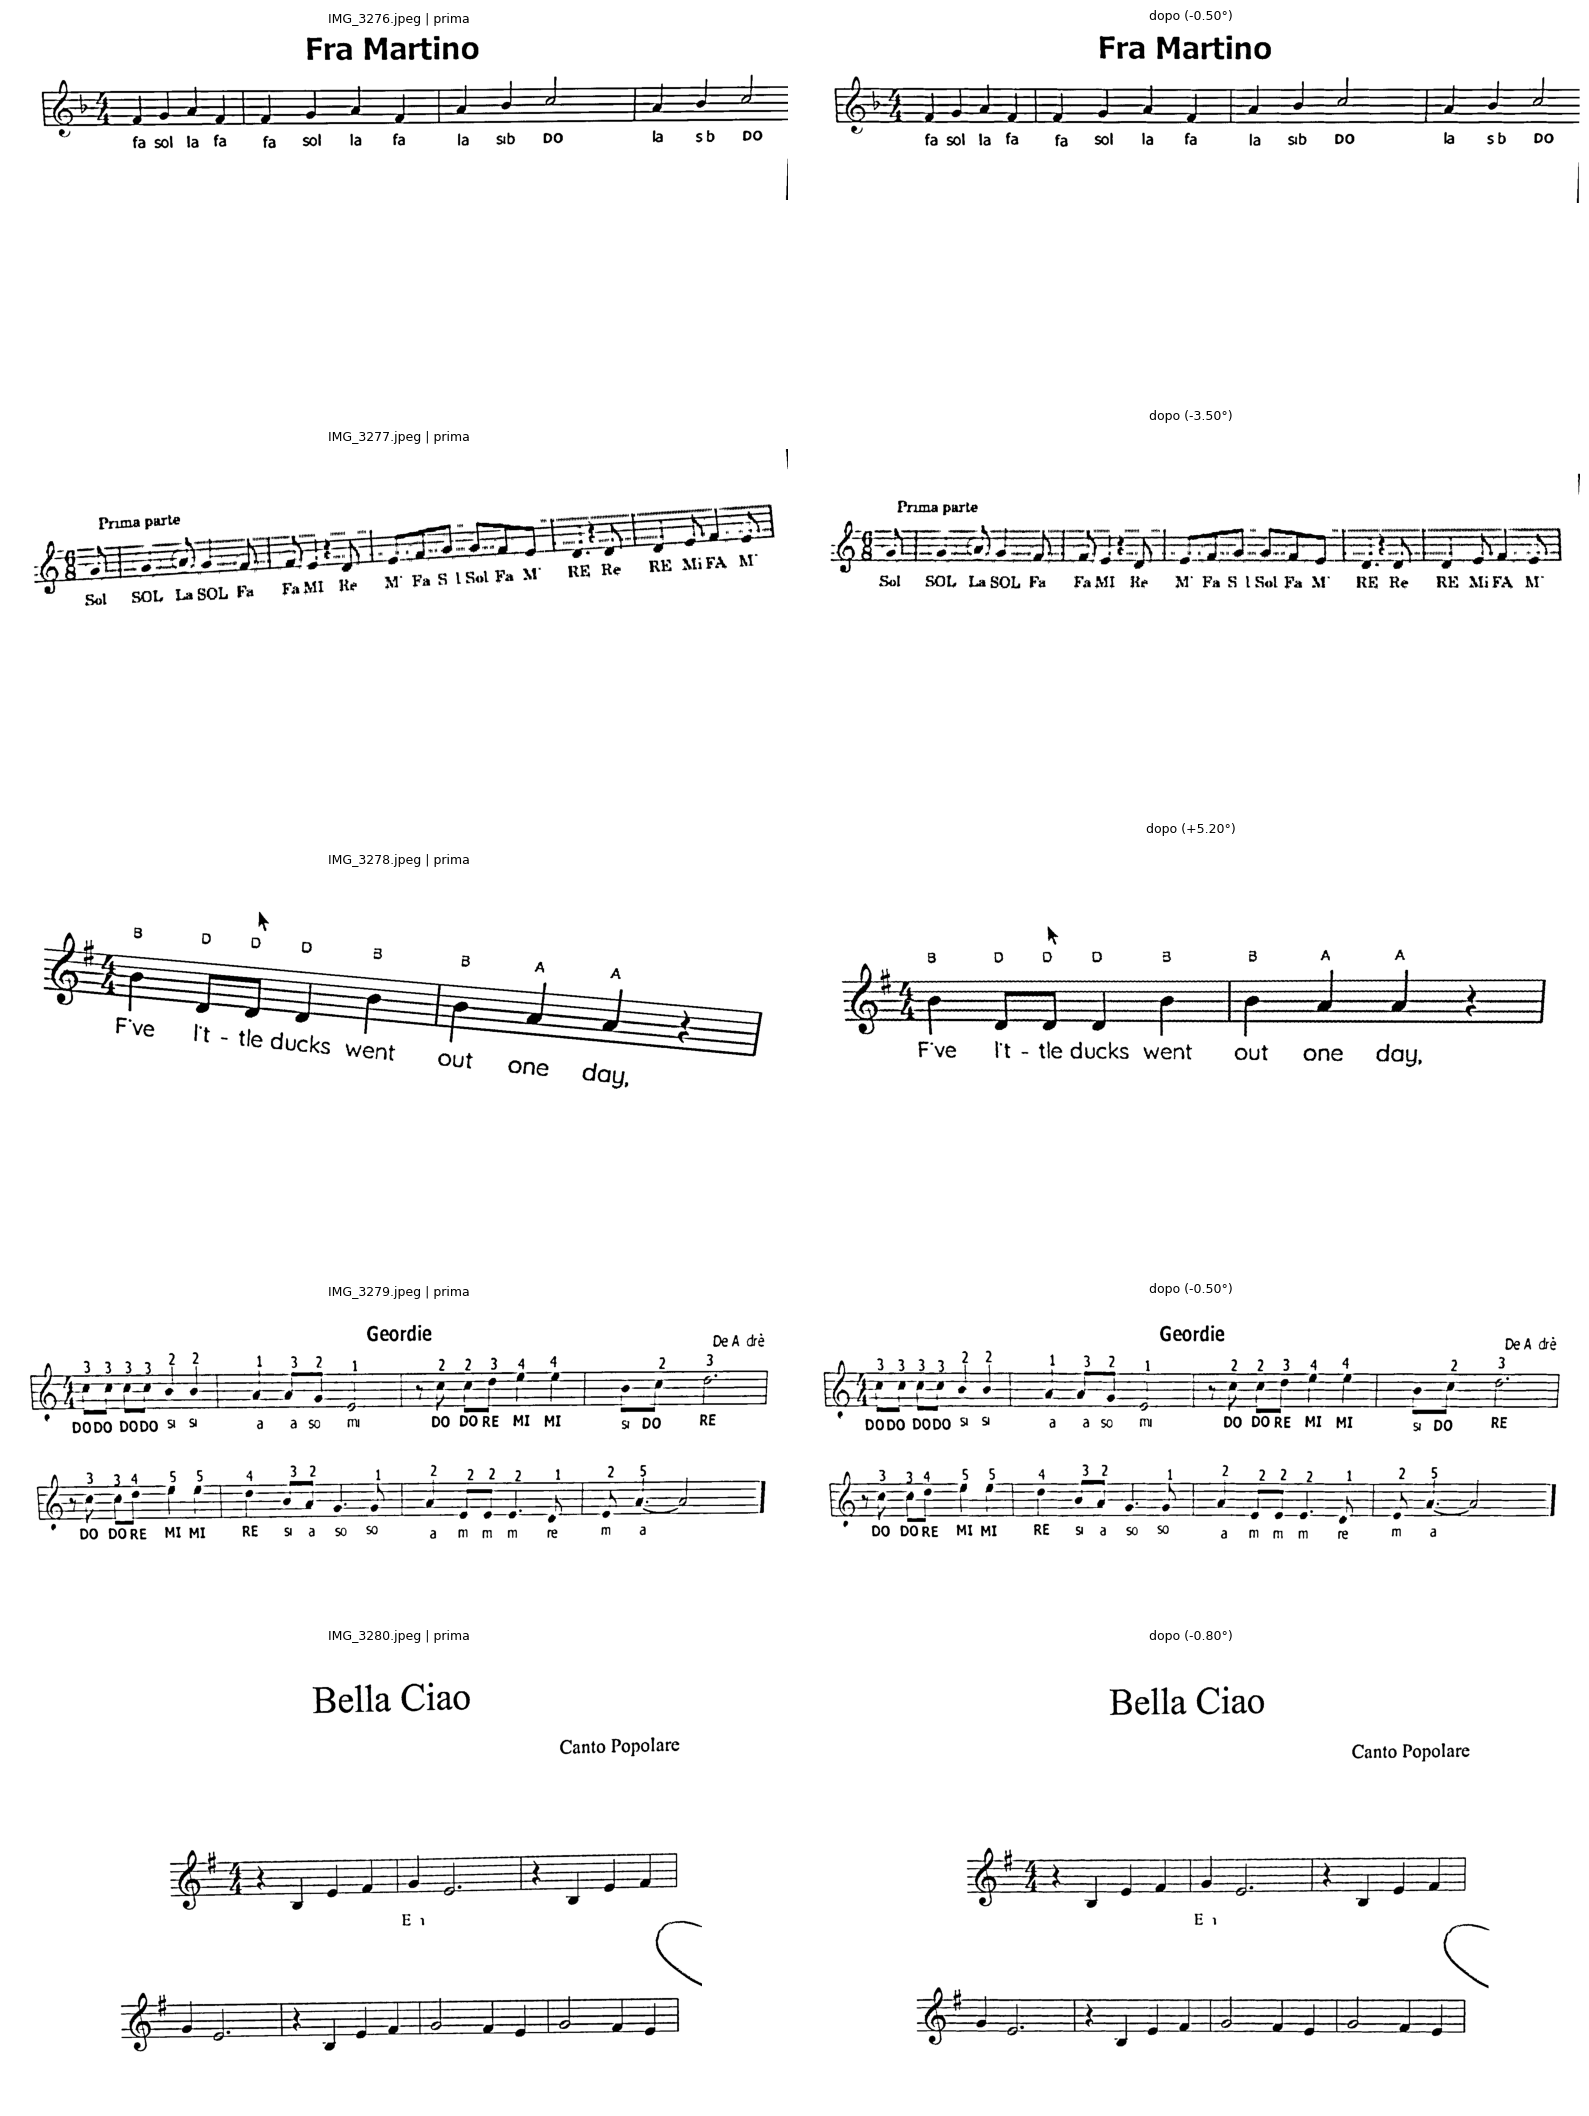

In [13]:
def angolo_hough(binaria):
    """Secondo metodo, indipendente: trova segmenti lunghi e quasi orizzontali."""
    ink = (binaria == 0).astype(np.uint8) * 255
    linee = cv2.HoughLinesP(ink, 1, np.pi / 720, threshold=200, minLineLength=400, maxLineGap=20)
    if linee is None:
        return None
    angoli = [np.degrees(np.arctan2(y2 - y1, x2 - x1)) for x1, y1, x2, y2 in linee.reshape(-1, 4)]
    angoli = [a for a in angoli if abs(a) < 15]
    return float(np.median(angoli)) if angoli else None

fig, assi = plt.subplots(len(FOTO), 2, figsize=(16, 4.5 * len(FOTO)))
for riga, f in zip(assi, FOTO):
    _, grigio = carica(f)
    b = binarizza(grigio)
    r, ang = raddrizza(b)
    print(f"{os.path.basename(f):32s} stimato={ang:+.2f}  Hough prima={angolo_hough(b)}  "
          f"stimato dopo={stima_angolo(r):+.2f}  Hough dopo={angolo_hough(r)}")
    riga[0].imshow(b, cmap='gray'); riga[0].set_title(f"{os.path.basename(f)} | prima", fontsize=9)
    riga[1].imshow(r, cmap='gray'); riga[1].set_title(f"dopo ({ang:+.2f}°)", fontsize=9)
    for ax in riga: ax.axis('off')
plt.tight_layout(); plt.show()